In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
def to_count(s):
    return pd.to_numeric(s.replace('-', 0), errors='raise').astype(int)

In [3]:
registrations_by_brands_sep2026 = pd.read_excel('../data/raw/fz28_2026_09.xlsx', header=None, sheet_name="FZ 28.4")
registrations_by_brands_ytd2526 = pd.read_excel('../data/raw/fz28_2026_09.xlsx', header=None, sheet_name="FZ 28.5")


brands_sep2026 = registrations_by_brands_sep2026.iloc[12:79, 1].str.lower().str.strip()

total_registrations_sep2026 = to_count(registrations_by_brands_sep2026.iloc[12:79, 2])
electric_drive_registrations_sep2026 = to_count(registrations_by_brands_sep2026.iloc[12:79,5])
bev_registrations_sep2026 = to_count(registrations_by_brands_sep2026.iloc[12:79, 7])
phev_registrations_sep2026 = to_count(registrations_by_brands_sep2026.iloc[12:79, 9])


brands_jan_sep = registrations_by_brands_ytd2526.iloc[12:82, 1].str.lower().str.strip()

total_registrations_ytd26 = to_count(registrations_by_brands_ytd2526.iloc[12:82, 2])
electric_drive_registrations_ytd26 = to_count(registrations_by_brands_ytd2526.iloc[12:82, 5])
bev_registrations_ytd26 = to_count(registrations_by_brands_ytd2526.iloc[12:82, 7])
phev_registrations_ytd26 = electric_drive_registrations_ytd26 - bev_registrations_ytd26

total_registrations_ytd25 = to_count(registrations_by_brands_ytd2526.iloc[12:82, 9])
electric_drive_registrations_ytd25 = to_count(registrations_by_brands_ytd2526.iloc[12:82, 12])
bev_registrations_ytd25 = to_count(registrations_by_brands_ytd2526.iloc[12:82, 14])
phev_registrations_ytd25 = electric_drive_registrations_ytd25 - bev_registrations_ytd25


assert (electric_drive_registrations_sep2026 - bev_registrations_sep2026 == phev_registrations_sep2026).all()
assert (bev_registrations_sep2026 + phev_registrations_sep2026 <= total_registrations_sep2026).all()
assert (bev_registrations_ytd26 + phev_registrations_ytd26 <= total_registrations_ytd26).all()
assert (bev_registrations_ytd25 + phev_registrations_ytd25 <= total_registrations_ytd25).all()

registrations_by_brands_sep2026_filtered = pd.DataFrame({
    'brand': brands_sep2026,    
    'total_sep26': total_registrations_sep2026,
    'bev_sep26': bev_registrations_sep2026,
    'phev_sep26': phev_registrations_sep2026
}).reset_index(drop=True)



registrations_by_brands_jan_sep_filtered = pd.DataFrame({
    'brand': brands_jan_sep,
    'total_ytd26': total_registrations_ytd26,
    'bev_ytd26': bev_registrations_ytd26,
    'phev_ytd26': phev_registrations_ytd26 ,
    'total_ytd25' : total_registrations_ytd25,
    'bev_ytd25': bev_registrations_ytd25,
    'phev_ytd25': phev_registrations_ytd25,
    
}).reset_index(drop=True)


sep_cols = ['total_sep26', 'bev_sep26', 'phev_sep26']

final_df = registrations_by_brands_sep2026_filtered.merge(
    registrations_by_brands_jan_sep_filtered,
    how='outer',
    indicator=True,
    on='brand',
    validate='one_to_one'
)


final_df[sep_cols] = final_df[sep_cols].fillna(0).astype(int)



assert (final_df['_merge'] != 'left_only').all()

final_df = final_df.drop(columns='_merge')

final_df = final_df.sort_values('brand').reset_index(drop=True)



assert registrations_by_brands_sep2026.iloc[79, 1].strip().lower() == 'insgesamt'
assert registrations_by_brands_sep2026.iloc[79,2] == total_registrations_sep2026.sum()
assert registrations_by_brands_sep2026.iloc[79,5] == electric_drive_registrations_sep2026.sum()
assert registrations_by_brands_sep2026.iloc[79,7] == bev_registrations_sep2026.sum()
assert registrations_by_brands_sep2026.iloc[79,9] == phev_registrations_sep2026.sum()


assert registrations_by_brands_ytd2526.iloc[82, 1].strip().lower() == 'insgesamt'
assert registrations_by_brands_ytd2526.iloc[82,2] == total_registrations_ytd26.sum()
assert registrations_by_brands_ytd2526.iloc[82,5] == electric_drive_registrations_ytd26.sum()
assert registrations_by_brands_ytd2526.iloc[82,7] == bev_registrations_ytd26.sum()


assert registrations_by_brands_ytd2526.iloc[82,9] == total_registrations_ytd25.sum()
assert registrations_by_brands_ytd2526.iloc[82,12] == electric_drive_registrations_ytd25.sum()
assert registrations_by_brands_ytd2526.iloc[82,14] == bev_registrations_ytd25.sum()


market = final_df[['total_ytd26', 'total_ytd25', 'bev_ytd26', 'bev_ytd25',
                      'phev_ytd26', 'phev_ytd25']].sum()

market_growth = {t: (market[f'{t}_ytd26'] - market[f'{t}_ytd25']) / market[f'{t}_ytd25'] * 100
                 for t in ['total', 'bev', 'phev']}
print(market_growth)

for t in ['total', 'bev', 'phev']:
    final_df[f'{t}_growth_ytd'] = (
        (final_df[f'{t}_ytd26'] - final_df[f'{t}_ytd25'])
        / final_df[f'{t}_ytd25'].replace(0, np.nan)
        * 100
    )

periods = ['sep26', 'ytd26', 'ytd25']

for p in periods:
    final_df[f'market_share_total_{p}'] = final_df[f'total_{p}'] / final_df[f'total_{p}'].sum() * 100
    for t in ['bev', 'phev']:
        final_df[f'{t}_market_share_{p}'] = final_df[f'{t}_{p}'] / final_df[f'{t}_{p}'].sum() * 100
        final_df[f'internal_{t}_share_{p}'] = final_df[f'{t}_{p}'] / final_df[f'total_{p}'] * 100


metrics = ['market_share_total', 'bev_market_share', 'internal_bev_share',
              'phev_market_share', 'internal_phev_share']

for m in metrics:
       final_df[f'{m}_change_pp'] = final_df[f'{m}_ytd26'] - final_df[f'{m}_ytd25']

cols = [f'{m}_change_pp' for m in metrics]

growth_cols = ['brand','total_growth_ytd', 'bev_growth_ytd', 'phev_growth_ytd']


outperformers = final_df[
    (final_df['total_growth_ytd'] >= market_growth['total'])
    & (final_df['bev_growth_ytd'] >= market_growth['bev'])
    & (final_df['phev_growth_ytd'] >= market_growth['phev'])
].sort_values('total_growth_ytd', ascending=False)

display(outperformers[['brand', 'total_ytd26'] + growth_cols[1:] + cols].round(2))

{'total': np.float64(5.281119512042563), 'bev': np.float64(58.06929320097749), 'phev': np.float64(13.63271152901422)}


,brand,total_ytd26,total_growth_ytd,bev_growth_ytd,phev_growth_ytd,market_share_total_change_pp,bev_market_share_change_pp,internal_bev_share_change_pp,phev_market_share_change_pp,internal_phev_share_change_pp
6,byd,42788,262.06,128.87,465.87,1.37,0.84,-22.24,8.54,22.25
33,leapmotor,16044,261.27,295.40,48.78,0.51,1.50,8.14,0.09,-8.15
37,lynk & co,927,59.28,270.59,46.17,0.01,0.01,7.75,0.07,-7.75
57,skoda,186973,12.83,61.99,20.25,0.56,0.22,9.09,0.28,0.42
9,citroen,40696,9.95,213.66,157.24,0.08,0.95,18.40,0.08,0.52
50,opel,105375,6.13,64.60,17.65,0.04,0.14,6.97,0.03,0.21


In [4]:
car_data = pd.read_excel('../data/raw/fz10_2026_09.xlsx', sheet_name='Sheet1')

car_data = car_data.drop(index=0).reset_index(drop=True)



car_data = car_data[
    (~car_data['Marke'].str.strip().str.endswith('ZUSAMMEN', na=False)) &
    (~car_data['Marke'].str.strip().str.endswith('INSGESAMT', na=False))
].copy()

car_data['Marke'] = car_data['Marke'].ffill()


car_data = car_data.replace('-', 0)

column_mapping = {
    'Marke' : 'brand',
    'Modellreihe': 'model',
    'Insgesamt': 'total_sep_2026',
    'Unnamed: 3': 'total_jan_sep_2026',
    'Unnamed: 4': 'total_share_pct',
    'mit Dieselantrieb': 'diesel_sep_2026',
    "Unnamed: 6": 'diesel_jan_sep_2026',
    'Unnamed: 7': 'diesel_share_pct',
    "mit Hybridantrieb \n(incl. Plug-in-Hybrid)": 'hybrid_incl_phev_sep_2026',
    'Unnamed: 9': 'hybrid_incl_phev_jan_sep_2026',
    'Unnamed: 10': 'hybrid_incl_phev_share_pct',
    'Benzin-Hybridantrieb \n(incl. Plug-in-Hybrid)': 'petrol_hybrid_incl_phev_sep_2026',
    'Unnamed: 12': 'petrol_hybrid_incl_phev_jan_sep_2026',
    'Unnamed: 13': 'petrol_hybrid_incl_phev_share_pct',
    'Diesel-Hybridantrieb \n(incl. Plug-in-Hybrid)': 'diesel_hybrid_incl_phev_sep_2026',
    'Unnamed: 15': 'diesel_hybrid_incl_phev_jan_sep_2026',
    'Unnamed: 16': 'diesel_hybrid_incl_phev_share_pct',
    'Hybridantrieb \n(ohne Plug-in-Hybrid)': 'hybrid_non_plugin_sep_2026',
    'Unnamed: 18': 'hybrid_non_plugin_jan_sep_2026',
    'Unnamed: 19': 'hybrid_non_plugin_share_pct',
    'Benzin-Hybridantrieb \n(ohne Plug-in-Hybrid)': 'petrol_hybrid_non_plugin_sep_2026',
    'Unnamed: 21': 'petrol_hybrid_non_plugin_jan_sep_2026',
    'Unnamed: 22': 'petrol_hybrid_non_plugin_share_pct',
    'Diesel-Hybridantrieb \n(ohne Plug-in-Hybrid)': 'diesel_hybrid_non_plugin_sep_2026',
    'Unnamed: 24': 'diesel_hybrid_non_plugin_jan_sep_2026',
    'Unnamed: 25': 'diesel_hybrid_non_plugin_share_pct',
    'Plug-in-Hybridantrieb': 'phev_sep_2026',
    'Unnamed: 27': 'phev_jan_sep_2026',
    'Unnamed: 28': 'phev_share_pct',
    'Benzin-Plug-in-Hybridantrieb': 'petrol_phev_sep_2026',
    'Unnamed: 30': 'petrol_phev_jan_sep_2026',
    'Unnamed: 31': 'petrol_phev_share_pct',
    'Diesel-Plug-in-Hybridantrieb': 'diesel_phev_sep_2026',
    'Unnamed: 33': 'diesel_phev_jan_sep_2026',
    'Unnamed: 34': 'diesel_phev_share_pct',
    'mit Elektroantrieb (BEV)': 'bev_sep_2026',
    'Unnamed: 36': 'bev_jan_sep_2026',
    'Unnamed: 37': 'bev_share_pct',
    'mit Allradantrieb': 'all_wheel_drive_sep_2026',
    'Unnamed: 39': 'all_wheel_drive_jan_sep_2026',
    'Unnamed: 40': 'all_wheel_drive_share_pct',
    'Cabriolets': 'cabriolets_sep_2026',
    'Unnamed: 42': 'cabriolets_jan_sep_2026',
    'Unnamed: 43': 'cabriolets_share_pct'

}

car_data = car_data.rename(columns=column_mapping, errors='raise')


numeric_cols = car_data.columns.drop(['brand', 'model'])

car_data[numeric_cols] = car_data[numeric_cols].apply(
    pd.to_numeric,
    errors='raise'
)


car_data[car_data['brand'] == 'BMW'].filter(regex='^.*_pct$')

df = car_data.filter(regex=r'^(?!.*_jan_sep_).*$')


df_subset = df[
    (df['brand'] == 'BMW') &
    (
        (df['bev_sep_2026'] > 0) |
        (df['phev_sep_2026'] > 0)
    )
].copy()

df_subset['chargeable_vehicles'] = (
    df_subset['bev_sep_2026'] +
    df_subset['phev_sep_2026']
)

df_subset = df_subset[
    ['brand', 'model', 'bev_sep_2026',
     'phev_sep_2026', 'chargeable_vehicles']
]

print(df_subset.sort_values(by='chargeable_vehicles', ascending=False))

   brand     model  bev_sep_2026  phev_sep_2026  chargeable_vehicles
44   BMW        X1          1809            343                 2152
46   BMW        X3          1072            825                 1897
39   BMW       5ER           523            509                 1032
38   BMW       4ER           777              0                  777
48   BMW        X5             0            370                  370
37   BMW       3ER           140            193                  333
43   BMW        IX           218              0                  218
45   BMW        X2           136              0                  136
40   BMW       7ER            76             13                   89
51   BMW        XM             0             64                   64
36   BMW       2ER             0             32                   32
54   BMW  SONSTIGE             0              2                    2


In [5]:
final_df.to_parquet('../data/processed/brand_registrations.parquet', index=False)

In [6]:
fz28_2 = pd.read_excel('../data/raw/fz28_2026_09.xlsx', header=None, sheet_name='FZ 28.2')

months = {'Januar': 1, 'Februar': 2, 'März': 3, 'April': 4, 'Mai': 5, 'Juni': 6,
          'Juli': 7, 'August': 8, 'September': 9, 'Oktober': 10, 'November': 11, 'Dezember': 12}

rows = []
year_totals = {}
year = None

for _, r in fz28_2.iterrows():
    label = str(r[1]).strip()
    if label.startswith('Jahr') and 'insgesamt' in label:
        year = int(label.split()[1])
        year_totals[year] = {'total': r[2], 'bev': r[7], 'phev': r[9]}

    elif label in months and year is not None:
        rows.append({'year': year, 'month': months[label],
                    'total': r[2], 'bev': r[7], 'phev':r[9]})
        
national_monthly = pd.DataFrame(rows)
for c in ['total', 'bev', 'phev']:
    national_monthly[c] = to_count(national_monthly[c])

In [7]:
month_sums = national_monthly.groupby('year')['total'].sum()
bev_sums = national_monthly.groupby('year')['bev'].sum()
phev_sums = national_monthly.groupby('year')['phev'].sum()

for y, t in year_totals.items():
    assert month_sums[y] == int(t.get('total')), f'{y}: months {month_sums[y]} vs year row {t}'
    assert bev_sums[y] == int(t.get('bev')), f'{y}: {t} vs bev_sums {bev_sums[y]}'
    assert phev_sums[y] == int(t.get('phev'))

assert national_monthly.groupby('year').size().drop(2026).eq(12).all()
assert (national_monthly['year'] == 2026).sum() == 9

assert set(national_monthly['year']) == set(year_totals)
assert national_monthly.notna().all().all()

In [8]:
national_monthly['date'] = pd.to_datetime(national_monthly[['year', 'month']].assign(day=1))
assert national_monthly['date'].is_unique

national_monthly = national_monthly.sort_values('date').reset_index(drop=True)
national_monthly['bev_share'] = national_monthly['bev'] / national_monthly['total'] * 100
national_monthly['phev_share'] = national_monthly['phev'] / national_monthly['total'] * 100
national_monthly.to_parquet("../data/processed/national_monthly_registrations.parquet", index=False)

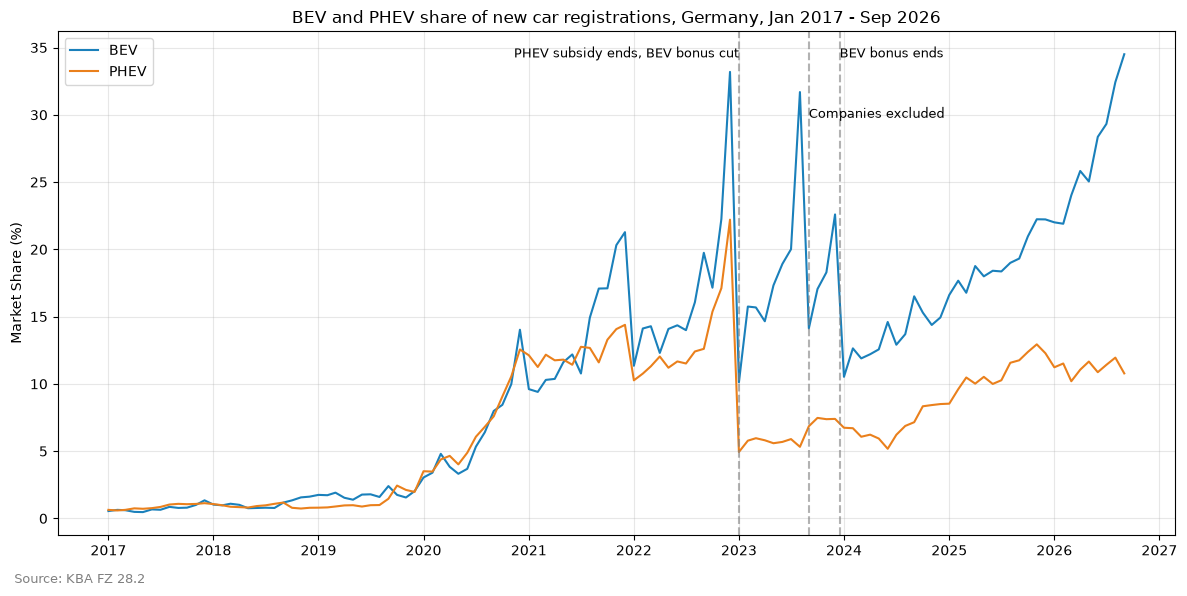

In [9]:
fig, ax = plt.subplots(figsize=(12,6))

ax.plot(
    national_monthly['date'],
    national_monthly['bev_share'],
    color='#1a80bb',
    label='BEV'
)

ax.plot(
    national_monthly['date'],
    national_monthly['phev_share'],
    color='#EA801C',
    label='PHEV'
)

ax.set(
    title="BEV and PHEV share of new car registrations, Germany, Jan 2017 - Sep 2026",
    ylabel='Market Share (%)'
)

events = [
    ("2023-01-01", "PHEV subsidy ends, BEV bonus cut", "right", 0.97),
    ("2023-09-01", "Companies excluded", "left", 0.85),
    ("2023-12-17", "BEV bonus ends", "left", 0.97),
]


for date, label, ha, height in events:
    date = pd.Timestamp(date)

    ax.axvline(date, color="grey", linestyle="--", alpha=0.6)

    ax.text(
        date, height, label,
        transform=ax.get_xaxis_transform(),
        ha=ha,
        va="top",
        fontsize=9
    )


ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.text(0.125,0.02,"Source: KBA FZ 28.2", fontsize=9, color='grey', ha='right')
fig.subplots_adjust(bottom=0.10)

plt.savefig("../reports/figures/national_ev_share_trend.png", dpi=150)
plt.show()